# Procurement Spend Analytics & Supplier Concentration
### City of Houston Checkbook — FY2024 · Real public vendor-payment data

**Analyst:** Jordan Shamukiga
**Framing:** Procurement / sourcing analysis for a Plant Buyer & Finance Business Analyst (cost-control) context

---

This notebook treats a municipal government as a large, multi-category buyer — the same
problem a plant or corporate procurement team faces: *where does the money go, who are the
critical suppliers, where is spend fragmented, and what can we consolidate?*

**Pipeline:** profile & clean → spend cube → ABC / Pareto → category & time segmentation →
supplier scorecard → savings sizing → sourcing recommendation.

> Every figure is computed at runtime from the raw file. Reusable logic lives in `src/utils.py`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import utils

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi':100,'axes.titleweight':'bold','axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.25})
INK,TEAL,SLATE,AMBER,CLAY,MUTE,GREEN = '#0f2e3d','#1f7a8c','#5c7a89','#e0a458','#bf4e30','#c9d6db','#2a9d8f'
def usd(x,p=None): return f'${x/1e6:,.0f}M' if abs(x)>=1e6 else f'${x:,.0f}'
RAW='../data/raw/checkbook-2024.csv'
print('Ready.')

Ready.


## 1. Load & profile the raw file — honestly

Before any analysis, look at what actually arrived: schema, size, date range, missingness.

In [2]:
raw = utils.load_checkbook(RAW)
print(f'Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n')
print('Columns:'); [print(f'  - {col}') for col in raw.columns]

Raw shape: 267,983 rows x 18 columns

Columns:
  - Payment Document Number
  - Fund ID
  - Fund Name
  - Department ID
  - Department Name
  - WBS ID
  - WBS Description
  - GL Account Number
  - GL Account Description
  - Vendor Name
  - Vendor Invoice
  - Fiscal Year
  - Clearing Date
  - Amount
  - Type of procurement
  - Purchase Order Number
  - Purchase Order Item
  - Contract Number


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [3]:
# Missingness — which fields are usable?
miss = ((raw.isna() | (raw=='')).mean()*100).round(2).sort_values(ascending=False)
miss.to_frame('pct_missing')

,pct_missing
WBS Description,92.54
WBS ID,92.54
Contract Number,29.32
Purchase Order Number,21.70
Vendor Invoice,2.51
Payment Document Number,0.00
Fund ID,0.00
Department Name,0.00
Department ID,0.00
Fund Name,0.00


**Read on missingness.** `WBS ID/Description` are ~93% empty (project-accounting fields used
only on capital work) — not useful as a spine. `Contract Number` is ~29% empty and `Purchase Order
Number` ~22% empty — expected, since not every payment runs through a formal contract/PO. The core
fields I need — **date, vendor, amount, department, GL category** — are fully populated. Good.

In [4]:
# Map the brief's generic fields -> Houston's actual column names
mapping = pd.DataFrame({
    'analysis_field':['payment date','vendor / payee','payment amount','department',
                      'expense category','fund','contract id','procurement type'],
    'houston_column':[utils.COLMAP['date'],utils.COLMAP['vendor'],utils.COLMAP['amount'],
                      utils.COLMAP['department'],utils.COLMAP['category'],utils.COLMAP['fund'],
                      utils.COLMAP['contract'],utils.COLMAP['proc_type']],
})
mapping

,analysis_field,houston_column
0,payment date,Clearing Date
1,vendor / payee,Vendor Name
2,payment amount,Amount
3,department,Department Name
4,expense category,GL Account Description
5,fund,Fund Name
6,contract id,Contract Number
7,procurement type,Type of procurement


In [5]:
# Raw amount + date behaviour (the two fields most likely to bite)
amt = pd.to_numeric(raw['Amount'], errors='coerce')
dt  = pd.to_datetime(raw['Clearing Date'], format='%m/%d/%Y', errors='coerce')
print('AMOUNT'); print(f'  min ${amt.min():,.0f}  max ${amt.max():,.0f}  median ${amt.median():,.0f}')
print(f'  negatives (refunds/reversals): {(amt<0).sum():,}  |  positives: {(amt>0).sum():,}')
print(f'\nDATE  range: {dt.min().date()} -> {dt.max().date()}   (Houston FY2024 = Jul-2023..Jun-2024)')
print(f'  unparseable dates: {dt.isna().sum()}')
print(f'\nCardinality: {raw["Vendor Name"].nunique():,} vendors, '
      f'{raw["GL Account Description"].nunique()} GL categories, '
      f'{raw["Department Name"].nunique()} departments')

AMOUNT
  min $-8,814,375  max $77,295,000  median $295
  negatives (refunds/reversals): 14,364  |  positives: 253,618

DATE  range: 2023-07-05 -> 2024-06-28   (Houston FY2024 = Jul-2023..Jun-2024)
  unparseable dates: 0

Cardinality: 4,189 vendors, 369 GL categories, 28 departments


### Data-quality issues found (and the cleaning decision for each)

| # | Issue | Decision |
|---|---|---|
| 1 | Exact-duplicate rows (repeat copies of an identical row) | Drop the repeats, keep one copy |
| 2 | `Constant In and Out` dept + `Vendor Disbursement` GL = pool-cash check-clearing | Drop — internal double-count, not spend |
| 3 | Negative amounts (refunds/reversals) | Exclude from spend totals (analysis uses gross payments); shown and reconciled to net below |
| 4 | Placeholder / one-time / refund pseudo-vendors (`*`, `GENERAL ONE-TIME VENDOR`, `COURTS REFUNDS`, water-refund bucket) | Drop — not suppliers you can source from |
| 5 | Vendor name casing/whitespace variants | Normalize to upper/trimmed |

All five are applied in `utils.clean_spend()`, which prints its funnel so nothing is hidden.

In [6]:
df = utils.clean_spend(raw)   # prints the cleaning funnel

Cleaning funnel (rows):
  raw                            267,983
  after drop exact dupes         266,757  (-1,226)
  after drop pool-cash/xfer      266,647  (-110)
  after keep positive spend      252,400  (-14,247)
  after drop pseudo-vendors      228,646  (-23,754)
  final spend rows               228,646
  total attributable spend    $  6,669,512,089


### Gross-to-net reconciliation

The spend totals in this notebook are **gross**: positive payments only. Refunds and reversals
(negative amounts) are excluded. The table below shows how much that excludes, and walks the raw
file down to the in-scope and addressable totals. For every line, gross + refunds/reversals = net,
and the three "Removed" lines plus "In-scope" add back to the raw file.

In [7]:
NONADDR = ['Revenue Bonds','Pension Payable','Bond Principal','Bond Interest','Principle Retirement',
           'Employee Claims','Payroll - 3rd Party','Municipal Pension','Annexation','Utilities Receivable',
           'Interest Charges Past Due','Juror Compensation','Grant Contract','Subrecipient','Sub-Recipient',
           'Receivable']
recon = utils.spend_reconciliation(raw, NONADDR)
r = recon.set_index('line')
# checks: removals + in-scope = raw; gross + refunds = net; gross in-scope = clean_spend total
parts = ['Removed: exact duplicates','Removed: pool-cash check clearing',
         'Removed: pseudo-vendors (one-time / refund)','In-scope vendor payments']
assert r.loc[parts,'rows'].sum() == r.loc['Raw file','rows']
assert abs(r.loc[parts,'net_usd'].sum() - r.loc['Raw file','net_usd']) < 1
assert ((recon['gross_usd'] + recon['refunds_reversals_usd'] - recon['net_usd']).abs() < 1).all()
assert abs(r.loc['In-scope vendor payments','gross_usd'] - df['amount'].sum()) < 1
assert r.loc['In-scope vendor payments','gross_rows'] == len(df)
recon.assign(gross_M=lambda d:(d['gross_usd']/1e6).round(1),
             refunds_M=lambda d:(d['refunds_reversals_usd']/1e6).round(1),
             net_M=lambda d:(d['net_usd']/1e6).round(1))[
    ['line','rows','gross_rows','gross_M','refund_reversal_rows','refunds_M','zero_rows','net_M']]

,line,rows,gross_rows,gross_M,refund_reversal_rows,refunds_M,zero_rows,net_M
0,Raw file,267983,253618,"6,767.20",14364,-673.80,1,"6,093.30"
1,Removed: exact duplicates,1226,1218,2.40,8,-0.30,0,2.10
2,Removed: pool-cash check clearing,110,0,0.00,110,-18.60,0,-18.60
3,Removed: pseudo-vendors (one-time / refund),23914,23754,95.30,160,-0.30,0,95.00
4,In-scope vendor payments,242733,228646,"6,669.50",14086,-654.70,1,"6,014.80"
5,of which non-addressable,20583,20479,"2,907.90",104,-0.20,0,"2,907.60"
6,of which addressable procurement,222150,208167,"3,761.70",13982,-654.50,1,"3,107.20"


In [8]:
# The refunds/reversals removed from in-scope spend: largest categories
ref = utils.inscope_refunds(raw, NONADDR)
print(f'{len(ref):,} in-scope refund/reversal rows, ${ref["amount"].sum():,.0f} in total '
      f'(${ref.loc[ref["addressable"],"amount"].sum():,.0f} in addressable categories)')
(ref.groupby('GL Account Description')['amount'].agg(['size','sum'])
    .rename(columns={'size':'rows','sum':'refunds_usd'})
    .sort_values('refunds_usd').head(10))

14,086 in-scope refund/reversal rows, $-654,732,267 in total ($-654,499,698 in addressable categories)


,rows,refunds_usd
GL Account Description,,
General Vendor - Primary Reconciliation Account,4213,"-597,073,561.52"
AUC - Stored Materials,142,"-44,287,945.51"
Construction Site Work Services,49,"-4,318,419.38"
Early Payment Discount,6654,"-2,210,707.74"
Refuse Disposal,19,"-1,234,566.87"
Engineering Services,8,"-693,787.49"
Cap Exp -Infrastruct,1,"-591,299.80"
Building Maintenance Services,76,"-480,739.78"
Vehicle Repair & Maintenance Supplies,1556,"-359,129.51"


## 2. The addressable-spend correction — the first real finding

Naively, the biggest "vendor" is **The Bank of New York at $1.18B (18%)**. That is *not* something
a buyer can negotiate — it's debt-service/trustee cash movement. Pension transfers, bond principal
& interest, employee-claims payouts and payroll reconciliation are all **non-addressable**: real
dollars, but outside procurement's control.

Any honest spend analysis has to separate **addressable procurement** from financial plumbing first,
or every downstream number is wrong.

In [9]:
df['addressable'] = ~df['category'].str.contains('|'.join(NONADDR), case=False, na=False)
addr = df[df['addressable']].copy()

TOTAL, ADDR = df['amount'].sum(), addr['amount'].sum()
print(f'Total FY24 vendor payments : ${TOTAL:,.0f}')
print(f'Non-addressable (finance)  : ${TOTAL-ADDR:,.0f}  ({(TOTAL-ADDR)/TOTAL*100:.1f}%)')
print(f'ADDRESSABLE PROCUREMENT    : ${ADDR:,.0f}  ({ADDR/TOTAL*100:.1f}%)')
print(f'  across {addr["vendor"].nunique():,} vendors and {addr["category"].nunique()} categories')

Total FY24 vendor payments : $6,669,512,089
Non-addressable (finance)  : $2,907,859,395  (43.6%)
ADDRESSABLE PROCUREMENT    : $3,761,652,694  (56.4%)
  across 3,701 vendors and 278 categories


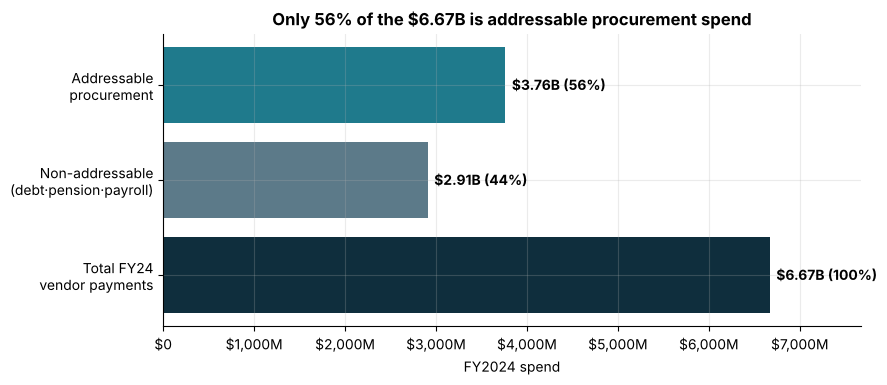

In [10]:
fig, ax = plt.subplots(figsize=(9,3.8))
vals=[TOTAL, TOTAL-ADDR, ADDR]; labs=['Total FY24\nvendor payments','Non-addressable\n(debt·pension·payroll)','Addressable\nprocurement']
b=ax.barh(labs, vals, color=[INK,SLATE,TEAL])
for bar,v in zip(b,vals): ax.text(v,bar.get_y()+bar.get_height()/2,f'  ${v/1e9:.2f}B ({v/TOTAL*100:.0f}%)',va='center',fontweight='bold')
ax.set_xlim(0,TOTAL*1.15); ax.xaxis.set_major_formatter(mticker.FuncFormatter(usd))
ax.set_title('Only 56% of the $6.67B is addressable procurement spend'); ax.set_xlabel('FY2024 spend'); plt.show()

In [11]:
# What did we set aside? The non-addressable top categories, for transparency.
utils.spend_cube(df[~df['addressable']], 'category').head(8)[['category','spend','txns']]

,category,spend,txns
19,Revenue Bonds Principle Retirement,"468,406,263.95",31
12,Payroll - 3rd Party Vendor Reconciliation Account,"434,396,581.57",1700
18,Revenue Bonds Interest,"361,111,095.66",149
0,Employee Claims Payable,"357,344,909.50",138
4,Non-Sub-Recipient Grant Contract,"268,906,685.29",2245
9,PR Municipal Pension Payable - Employer,"199,766,451.23",41
15,Public Improvement Bond Principal Retirement,"179,545,000.00",9
11,PR Police Pension Payable - Employer,"155,763,072.00",31


## 3. Spend cube

A tidy cube lets us slice spend by any dimension. Here: department and procurement mechanism.

In [12]:
by_dept = utils.spend_cube(addr,'department').head(12).copy()
by_dept['spend_M']=(by_dept['spend']/1e6).round(1)
by_dept[['department','spend_M','txns','vendors']]

,department,spend_M,txns,vendors
18,Houston Public Works - HPW,"1,555.70",36215,1035
12,Houston Airport System (HAS),811.50,11565,585
22,Mayor's Office,371.80,1138,197
10,General Services Department,153.40,13037,116
19,Human Resources Dept.,125.20,21266,141
4,Citywide General Government,85.40,1491,107
26,Solid Waste Management,72.60,3399,258
16,Houston Information Tech Svcs,67.30,4553,138
15,Houston Health Department,66.60,10612,452
17,Houston Police Department-HPD,63.50,4784,310


In [13]:
utils.spend_cube(addr,'proc_type').assign(spend_M=lambda d:(d["spend"]/1e6).round(1))[['proc_type','spend_M','txns','vendors']]

,proc_type,spend_M,txns,vendors
0,PO Cap Proj Release,"1,717.50",13557,331
7,Service Rel. Order,853.80,69291,556
8,Vendor Invoice,726.40,10246,1255
1,PO Contract Release,244.00,43648,521
3,PO Interlocal,92.50,2486,192
2,PO Emergency,62.50,2208,118
5,PO One-time,43.40,14313,1426
4,PO MarketPlace Order,16.20,51577,20
6,PO Sole Source,5.50,841,155


## 4. ABC / Pareto — supplier concentration & tail spend

Classic procurement segmentation:
**A** = suppliers making up the first 80% of spend, **B** = next 15%, **C** = the 5% tail.
This is where you decide where to spend negotiating energy.

In [14]:
abc = utils.abc_classify(addr,'vendor')
summ = utils.abc_summary(abc,'vendor')
disp = summ.assign(pct_vendors=lambda d:(d['pct_entities']*100).round(1),
                   pct_spend=lambda d:(d['pct_spend']*100).round(1),
                   spend_M=lambda d:(d['spend']/1e6).round(0))
disp[['abc','n_vendors','pct_vendors','spend_M','pct_spend']]

,abc,n_vendors,pct_vendors,spend_M,pct_spend
0,A,159,4.30,"3,007.00",79.90
1,B,336,9.10,567.00,15.10
2,C,3206,86.60,188.00,5.00


In [15]:
n80=int((abc['cum_share']<=0.80).sum())+1
print(f'{n80} of {len(abc):,} vendors ({n80/len(abc)*100:.1f}%) account for 80% of addressable spend.')
print(f'The bottom {(abc["abc"]=="C").sum():,} tail vendors (Class C) together are just 5% of spend'
      f' — but that is ${summ.set_index("abc").loc["C","spend"]:,.0f} and a huge admin/PO burden.')
print(f'Vendor-spend HHI = {utils.hhi(addr.groupby("vendor")["amount"].sum()):.0f} '
      f'(low — spread across many suppliers once trustee flows are removed).')

160 of 3,701 vendors (4.3%) account for 80% of addressable spend.
The bottom 3,206 tail vendors (Class C) together are just 5% of spend — but that is $188,099,833 and a huge admin/PO burden.
Vendor-spend HHI = 124 (low — spread across many suppliers once trustee flows are removed).


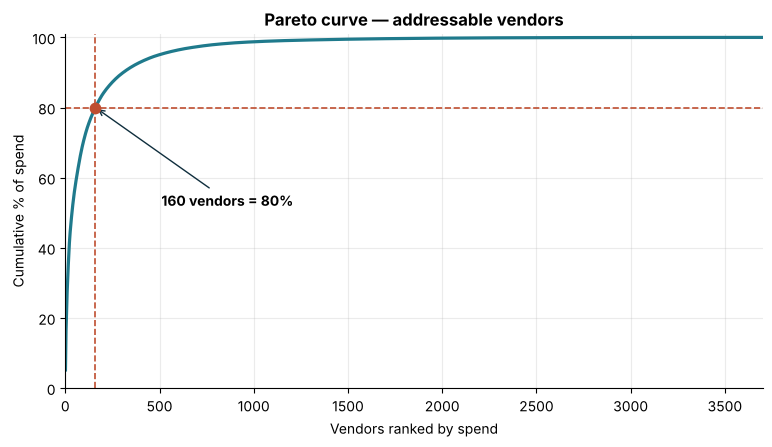

In [16]:
fig,ax=plt.subplots(figsize=(9,4.6))
ax.plot(abc['rank'], abc['cum_share']*100, color=TEAL, lw=2.3)
ax.axhline(80,color=CLAY,ls='--',lw=1.2); ax.axvline(n80,color=CLAY,ls='--',lw=1.2)
ax.scatter([n80],[80],color=CLAY,s=55,zorder=5)
ax.annotate(f'{n80} vendors = 80%',(n80,80),xytext=(n80+350,52),
            arrowprops=dict(arrowstyle='->',color=INK),fontweight='bold')
ax.set_xlim(0,len(abc)); ax.set_ylim(0,101)
ax.set_xlabel('Vendors ranked by spend'); ax.set_ylabel('Cumulative % of spend')
ax.set_title('Pareto curve — addressable vendors'); plt.show()

In [17]:
# Top 15 addressable suppliers
top=abc.head(15).assign(spend_M=lambda d:(d['amount']/1e6).round(1),
                        share=lambda d:(d['spend_share']*100).round(1))
top[['rank','vendor','spend_M','share']]

,rank,vendor,spend_M,share
0,1,HENSEL PHELPS CONSTRUCTION CO,194.70,5.20
1,2,HOUSTON WATERWORKS TEAM,170.30,4.50
2,3,AUSTIN GILBANE A JOINT VENTURE,164.60,4.40
3,4,RELIANT ENERGY RETAIL SERVICES LLC,84.90,2.30
4,5,FLATIRON CONSTRUCTORS INC,75.70,2.00
5,6,REYTEC CONSTRUCTION RESOURCES INC,74.30,2.00
6,7,HARPER BROTHERS CONSTRUCTION LLC,72.00,1.90
7,8,INDUSTRIAL TX CORP,69.10,1.80
8,9,MAIN LANE INDUSTRIES LTD,63.80,1.70
9,10,ARCHER WESTERN CONSTRUCTION LLC,62.60,1.70


**The surprise inside the head.** Even after stripping trustee flows, `THE BANK OF NEW YORK`
still reappears further down (~$49M) under a services GL with **no contract number on any of its
payments and the widest payment-size dispersion among the top 15** — spend that may be coded to the
wrong bucket, which the scorecard picks up in §6. The genuine top of the addressable list is **heavy-construction & water-infrastructure
JVs** (Hensel Phelps, Houston Waterworks Team, Austin-Gilbane) — capital programs, not repeatable
buys.

## 5. Category & time segmentation

Where does addressable spend concentrate by category, and does it move through the year?

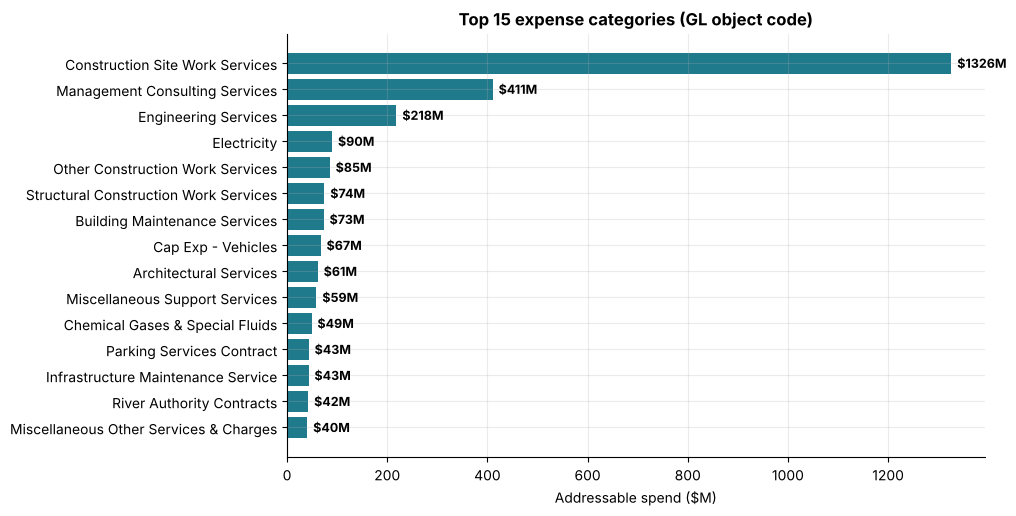

In [18]:
cat=utils.spend_cube(addr,'category').head(15).iloc[::-1]
fig,ax=plt.subplots(figsize=(9,5.5))
ax.barh(cat['category'].str.slice(0,40), cat['spend']/1e6, color=TEAL)
for i,v in enumerate(cat['spend']): ax.text(v/1e6,i,f'  ${v/1e6:.0f}M',va='center',fontsize=9,fontweight='bold')
ax.set_xlabel('Addressable spend ($M)'); ax.set_title('Top 15 expense categories (GL object code)'); plt.show()

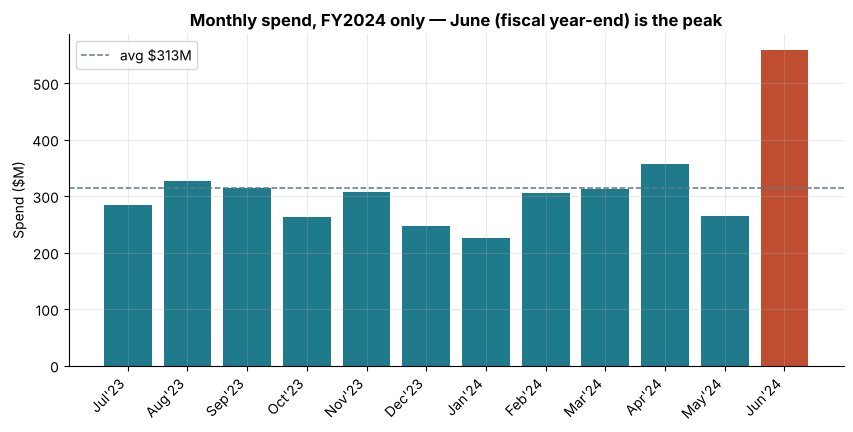

Peak: 2024-06 at $558M = +78% vs the monthly average.
Low:  2024-01 at $225M = -28% vs the monthly average.
One fiscal year of data: this is FY2024's pattern, not a tested multi-year seasonal effect.


month,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06
vs_avg_pct,-10.00,4.00,0.00,-16.00,-2.00,-21.00,-28.00,-3.00,-1.00,14.00,-15.00,78.00


In [19]:
seas=utils.seasonality(addr)
fig,ax=plt.subplots(figsize=(10,4.3))
months=pd.to_datetime(seas['month']+'-01')
cols=[CLAY if s==seas['spend'].max() else TEAL for s in seas['spend']]
ax.bar(range(len(seas)), seas['spend']/1e6, color=cols)
ax.set_xticks(range(len(seas))); ax.set_xticklabels([m.strftime("%b'%y") for m in months],rotation=45,ha='right')
avg=seas['spend'].mean()/1e6; ax.axhline(avg,color=SLATE,ls='--',lw=1.1,label=f'avg ${avg:.0f}M')
ax.set_ylabel('Spend ($M)'); ax.legend()
ax.set_title('Monthly spend, FY2024 only — June (fiscal year-end) is the peak'); plt.show()
seas['vs_avg_pct']=(seas['spend']/seas['spend'].mean()*100-100).round(0)
pk=seas.loc[seas['spend'].idxmax()]; lo=seas.loc[seas['spend'].idxmin()]
print(f"Peak: {pk['month']} at ${pk['spend']/1e6:.0f}M = {pk['vs_avg_pct']:+.0f}% vs the monthly average.")
print(f"Low:  {lo['month']} at ${lo['spend']/1e6:.0f}M = {lo['vs_avg_pct']:+.0f}% vs the monthly average.")
print('One fiscal year of data: this is FY2024\'s pattern, not a tested multi-year seasonal effect.')
seas[['month','vs_avg_pct']].set_index('month').T

**Seasonality read (FY2024 only).** In this fiscal year, June (fiscal year-end) ran **+78% above
the monthly average** and January was the low month (−28%). That fits a year-end budget push, but it
is one year's pattern: confirming it as a recurring effect needs the other years of the checkbook,
and this file has no prices, so it says nothing about whether June buys cost more. If the pattern
holds across years, it is a reason to look at moving discretionary buys earlier in the year.

## 6. Supplier scorecard

Scored on the dimensions **public spend data can actually support**: total spend, order/payment
frequency, ticket size, payment-size dispersion (coefficient of variation of payment amounts — how
much payment sizes vary, not a measure of price changes), relationship breadth (active months), and
contract coverage (share of spend on payments that carry a contract number).

A **payment-regularity** field stands in as an *on-time proxy* — the checkbook has no PO-date vs
pay-date pair, so true lead-time/on-time delivery is not computable here and I say so rather than
fake it.

In [20]:
sc = utils.supplier_scorecard(addr, top_n=15)
show = sc.assign(spend_M=lambda d:(d['total_spend']/1e6).round(1),
                 avg_k=lambda d:(d['avg_txn']/1e3).round(0),
                 pay_size_disp=lambda d:d['payment_size_dispersion'].round(2),
                 contract=lambda d:(d['contract_coverage']*100).round(0))
show[['vendor','spend_M','txns','avg_k','pay_size_disp','active_months','contract']]

,vendor,spend_M,txns,avg_k,pay_size_disp,active_months,contract
0,HENSEL PHELPS CONSTRUCTION CO,194.70,119,"1,636.00",1.59,12,90.00
1,HOUSTON WATERWORKS TEAM,170.30,102,"1,669.00",2.12,12,99.00
2,AUSTIN GILBANE A JOINT VENTURE,164.60,633,260.00,1.86,11,98.00
3,RELIANT ENERGY RETAIL SERVICES LLC,84.90,256,331.00,1.92,12,100.00
4,FLATIRON CONSTRUCTORS INC,75.70,119,636.00,1.53,10,97.00
5,REYTEC CONSTRUCTION RESOURCES INC,74.30,523,142.00,2.47,12,95.00
6,HARPER BROTHERS CONSTRUCTION LLC,72.00,173,416.00,1.10,12,90.00
7,INDUSTRIAL TX CORP,69.10,158,437.00,1.06,12,93.00
8,MAIN LANE INDUSTRIES LTD,63.80,208,307.00,1.48,12,95.00
9,ARCHER WESTERN CONSTRUCTION LLC,62.60,76,824.00,0.84,5,100.00


In [21]:
# Contract-coverage gaps: >$20M vendors where under half the spend carries a contract number.
# A blank contract number means the payment is not linked to a contract in this file. It does NOT
# mean the spend was unauthorized: payments to other public bodies, utilities, or invoices paid
# under other authority can legitimately have no contract number.
full = utils.supplier_scorecard(addr)
gap = full[(full['total_spend']>2e7) & (full['contract_coverage']<0.5)]
print(f'{len(gap)} vendors with >$20M addressable spend have <50% of it tagged with a contract number:')
gap.assign(spend_M=lambda d:(d['total_spend']/1e6).round(1),
           contract=lambda d:(d['contract_coverage']*100).round(0))[['vendor','spend_M','contract','payment_size_dispersion']]

8 vendors with >$20M addressable spend have <50% of it tagged with a contract number:


,vendor,spend_M,contract,payment_size_dispersion
12,THE BANK OF NEW YORK,49.40,0.00,2.97
18,UPTOWN DEVELOPMENT AUTHORITY,41.00,0.00,0.95
19,MIDTOWN REDEVELOPMENT,38.90,0.00,0.53
22,HOUSTON ISD,33.40,0.00,1.38
24,JPMORGAN CHASE BANK NATIONAL,26.40,0.00,0.08
26,TRISTAR RISK MANAGEMENT,24.20,9.00,0.72
28,CITY OF HOUSTON - TEXAS SINGLE,22.20,4.00,0.81
29,MAIN STREET MARKET SQUARE REDEVELOP,21.90,0.00,1.33


### The quality/defect dimension is deliberately out of scope

A production supplier scorecard needs **quality** — PPM defect rates, RMA/return counts, inspection
failures, on-time-in-full. Those live in an internal **ERP/QMS**, not in a public checkbook. I will
**not** invent them as if real.

Below I attach a **clearly-labelled SYNTHETIC** quality score *only* to show the scorecard's intended
shape for this portfolio demo. It is deterministic, flagged, and must never drive a real decision.

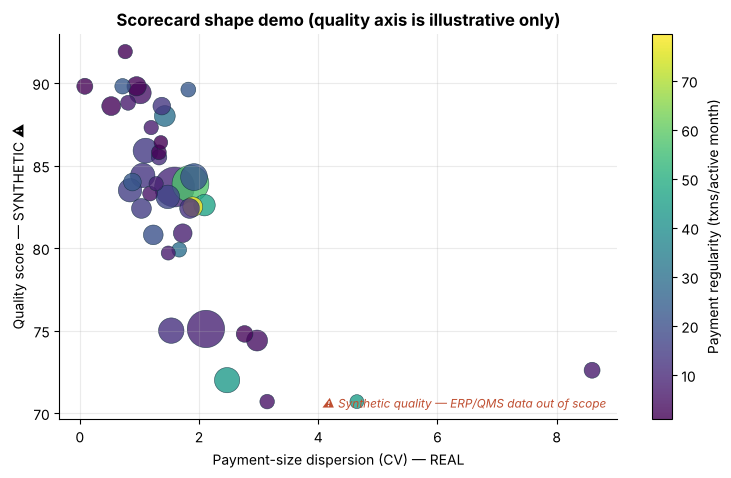

In [22]:
scq = utils.add_illustrative_quality(utils.supplier_scorecard(addr, top_n=40))
fig,ax=plt.subplots(figsize=(9,5))
sizes=(scq['total_spend']/scq['total_spend'].max()*800)+25
s=ax.scatter(scq['payment_size_dispersion'], scq['quality_score_SYNTH'], s=sizes,
             c=scq['regularity_proxy'], cmap='viridis', alpha=0.8, edgecolor=INK, lw=0.4)
ax.set_xlabel('Payment-size dispersion (CV) — REAL'); ax.set_ylabel('Quality score — SYNTHETIC ⚠')
ax.set_title('Scorecard shape demo (quality axis is illustrative only)')
plt.colorbar(s,label='Payment regularity (txns/active month)')
ax.text(0.98,0.03,'⚠ Synthetic quality — ERP/QMS data out of scope',transform=ax.transAxes,
        ha='right',fontsize=8.5,style='italic',color=CLAY); plt.show()

## 7. Fragmentation & consolidation scenario sizing

Fragmentation = many vendors serving one category with low top-3 concentration. That's where
consolidating onto a few awarded suppliers unlocks volume leverage. I target **indirect / services**
categories (repeatable, easy to compete) — not one-off capital construction.

The savings figures below are **scenario sizing, not estimates from the data**: they apply assumed
savings rates of 5% / 8% / 12% to the tail spend outside each category's top 3 vendors. The data
supplies the tail pool; the rates are assumptions.

In [23]:
frag=utils.fragmentation_table(addr, min_vendors=10)
cand=frag[frag['spend']>2.5e7].copy()
cand['consolidation_score']=(cand['n_vendors']*(1-cand['top3_share'])).round(0)
cand=cand.sort_values('consolidation_score',ascending=False).head(10)
cand.assign(spend_M=lambda d:(d['spend']/1e6).round(0),
            top3=lambda d:(d['top3_share']*100).round(0),
            tail_M=lambda d:(d['tail_spend']/1e6).round(1))[
    ['category','spend_M','n_vendors','top3','hhi','tail_M','consolidation_score']]

,category,spend_M,n_vendors,top3,hhi,tail_M,consolidation_score
11,Miscellaneous Other Services & Charges,40.00,531,49.00,"1,277.09",20.50,270.00
8,Miscellaneous Support Services,59.00,374,41.00,"1,161.95",34.60,221.00
1,Management Consulting Services,411.00,257,28.00,439.48,297.30,186.00
15,COH General Inventory Account,33.00,238,27.00,436.12,23.90,173.00
0,Construction Site Work Services,"1,326.00",229,31.00,489.18,918.90,159.00
7,Architectural Services,61.00,131,30.00,463.10,42.90,92.00
14,Other Equipment Services,37.00,111,46.00,"1,195.32",20.10,59.00
5,Building Maintenance Services,73.00,88,73.00,"3,158.43",19.90,24.00
9,Chemical Gases & Special Fluids,49.00,37,47.00,"1,150.26",25.70,19.00
2,Engineering Services,218.00,108,87.00,"6,124.29",29.40,15.00


In [24]:
targets=['Management Consulting Services','Architectural Services','Miscellaneous Support Services',
         'Miscellaneous Other Services & Charges','Temporary Personnel Services']
rows=[utils.size_consolidation_savings(addr,t,keep_vendors=3,savings_rate=0.08) for t in targets if t in addr['category'].values]
S=pd.DataFrame(rows)
S_disp=S.assign(spend_M=lambda d:(d['total_spend']/1e6).round(1),
                tail_M=lambda d:(d['tail_spend']/1e6).round(1),
                save_M=lambda d:(d['estimated_savings']/1e6).round(2))
print(S_disp[['category','spend_M','n_vendors','tail_vendors','tail_M','save_M']].to_string(index=False))
pool=S['tail_spend'].sum(); base=S['estimated_savings'].sum()
print(f'\nConsolidatable tail pool (5 indirect categories): ${pool:,.0f}')
print('Scenario sizing (assumed savings rate x tail pool):')
print(f'  5% assumption  = ${pool*0.05:,.0f}')
print(f'  8% assumption  = ${base:,.0f}')
print(f'  12% assumption = ${pool*0.12:,.0f}')

                              category  spend_M  n_vendors  tail_vendors  tail_M  save_M
        Management Consulting Services   410.60        257           254  297.30   23.79
                Architectural Services    61.40        131           128   42.90    3.43
        Miscellaneous Support Services    58.60        374           371   34.60    2.77
Miscellaneous Other Services & Charges    40.40        531           528   20.50    1.64
          Temporary Personnel Services    22.90         15            12    2.10    0.17

Consolidatable tail pool (5 indirect categories): $397,397,093
Scenario sizing (assumed savings rate x tail pool):
  5% assumption  = $19,869,855
  8% assumption  = $31,791,767
  12% assumption = $47,687,651


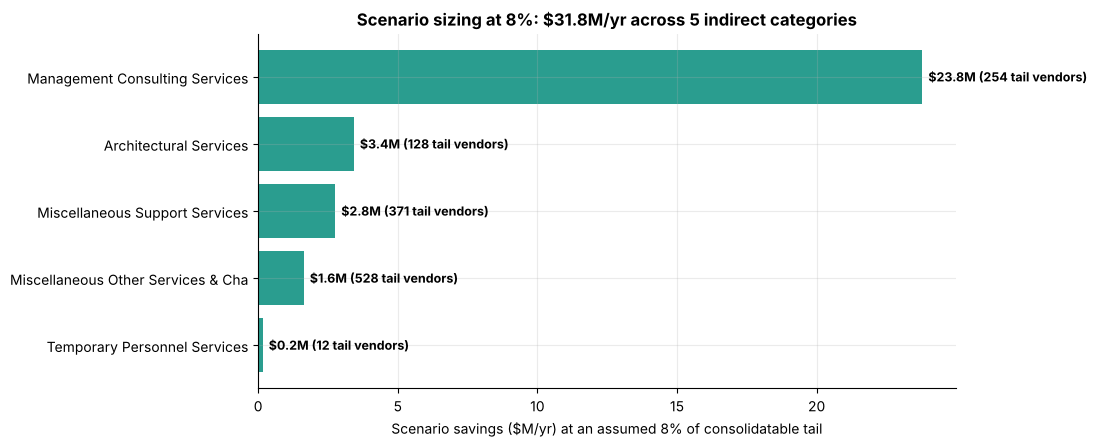

In [25]:
fig,ax=plt.subplots(figsize=(9,4.6))
Ss=S.sort_values('estimated_savings')
ax.barh(Ss['category'].str.slice(0,34), Ss['estimated_savings']/1e6, color=GREEN)
for i,(v,tv) in enumerate(zip(Ss['estimated_savings'],Ss['tail_vendors'])):
    ax.text(v/1e6,i,f'  ${v/1e6:.1f}M ({tv} tail vendors)',va='center',fontweight='bold',fontsize=9)
ax.set_xlabel('Scenario savings ($M/yr) at an assumed 8% of consolidatable tail')
ax.set_title(f'Scenario sizing at 8%: ${base/1e6:.1f}M/yr across 5 indirect categories'); plt.show()

### Derived tables written to disk

Everything above is computed in memory. These are the tables worth keeping: two large
intermediates under `data/processed/` (git-ignored, regenerated from the raw file), and four
small analyst-facing tables under `reports/` that are committed so a reviewer without the
268k-row source extract can still read the classification, the scorecard, the fragmentation
view and the gross-to-net reconciliation. Payee names that look like private individuals are
masked in the `reports/` tables (`utils.mask_individual_names`).

In [26]:
written = utils.export_tables(
    clean=df,
    addressable=addr,
    abc=abc,
    scorecard=utils.supplier_scorecard(addr),
    fragmentation=utils.fragmentation_table(addr, min_vendors=5),
    reconciliation=recon,
)
for label, path in written.items():
    print(f'{label:32s} -> {path}')

spend_clean                      -> ../data/processed/spend_clean.csv
spend_addressable                -> ../data/processed/spend_addressable.csv
abc_vendor_classification        -> ../reports/abc_vendor_classification.csv
supplier_scorecard_top50         -> ../reports/supplier_scorecard_top50.csv
category_fragmentation           -> ../reports/category_fragmentation.csv
gross_to_net_reconciliation      -> ../reports/gross_to_net_reconciliation.csv


In [27]:
# Headline metrics -> reports/spend_metrics.json (every value computed above)
import json
summ_i = summ.set_index('abc'); seas_i = seas.set_index('month')
def line(name): return {k: (int(v) if k.endswith('rows') else float(v))
                        for k, v in r.loc[name].items()}
metrics = {
  'dataset': 'City of Houston Checkbook FY2024 (real public data)',
  'date_range': [str(dt.min().date()), str(dt.max().date())],
  'raw_rows': int(len(raw)),
  'clean_spend_rows': int(len(df)),
  'addressable_rows': int(len(addr)),
  'spend_basis': 'gross: positive payments only; refunds/reversals excluded (see gross_to_net)',
  'total_vendor_payments_usd': round(float(TOTAL), 2),
  'addressable_spend_usd': round(float(ADDR), 2),
  'addressable_pct': round(float(ADDR/TOTAL), 4),
  'addressable_vendors': int(addr['vendor'].nunique()),
  'addressable_categories': int(addr['category'].nunique()),
  'hhi_addressable_vendor': round(utils.hhi(addr.groupby('vendor')['amount'].sum()), 1),
  'gross_to_net': {
    'raw_file': line('Raw file'),
    'removed_exact_duplicates': line('Removed: exact duplicates'),
    'removed_pool_cash': line('Removed: pool-cash check clearing'),
    'removed_pseudo_vendors': line('Removed: pseudo-vendors (one-time / refund)'),
    'in_scope': line('In-scope vendor payments'),
    'in_scope_non_addressable': line('  of which non-addressable'),
    'in_scope_addressable': line('  of which addressable procurement'),
  },
  'abc': {k: {'n_vendors': int(summ_i.loc[k,'n_vendors']),
              'pct_vendors': round(float(summ_i.loc[k,'pct_entities']), 4),
              'spend_usd': round(float(summ_i.loc[k,'spend']), 2),
              'pct_spend': round(float(summ_i.loc[k,'pct_spend']), 4)} for k in ['A','B','C']},
  'vendors_for_80pct': int(n80),
  'top_vendor': {'name': abc.iloc[0]['vendor'], 'spend_usd': round(float(abc.iloc[0]['amount']), 2),
                 'pct': round(float(abc.iloc[0]['spend_share']), 4)},
  'contract_coverage_gaps': {
    'definition': 'vendors with >$20M addressable spend and <50% of spend on rows with a contract number; '
                  'a blank contract number is a coverage gap in the file, not unauthorized spend',
    'n_vendors': int(len(gap)),
  },
  'consolidation_scenarios': {
    'note': 'scenario sizing: assumed savings rates applied to tail spend outside the top 3 vendors; '
            'the rates are assumptions, not estimated from the data',
    'categories': list(S['category']),
    'tail_pool_usd': round(float(pool), 2),
    'assumed_rates': [0.05, 0.08, 0.12],
    'scenario_at_5pct_usd': round(float(pool*0.05), 2),
    'scenario_at_8pct_usd': round(float(base), 2),
    'scenario_at_12pct_usd': round(float(pool*0.12), 2),
  },
  'seasonality': {
    'note': 'one fiscal year (FY2024) only; not a tested multi-year pattern',
    'peak_month': str(pk['month']),
    'peak_spend_usd': round(float(pk['spend']), 2),
    'peak_vs_avg_pct': round(float(pk['spend']/seas['spend'].mean()-1), 4),
    'trough_month': str(lo['month']),
    'trough_vs_avg_pct': round(float(lo['spend']/seas['spend'].mean()-1), 4),
  },
}
with open('../reports/spend_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print('WROTE ../reports/spend_metrics.json')

WROTE ../reports/spend_metrics.json


## 8. Sourcing recommendation

Grounded in what *this* dataset shows — specific, opinionated, costed.

**CONSOLIDATE — scenario sizing: ~$31.8M/yr at an assumed 8% (range $19.9M–$47.7M at 5%–12%)**
- **Management Consulting Services — $411M across 257 vendors, top-3 only 28%.** The single largest
  fragmentation problem. ~$297M sits in a long tail. Run a tiered RFP, award 5–8 primes on a rate
  card, and route work through them. At the assumed 8% rate on the tail this sizes at **$23.8M/yr** —
  most of the scenario total.
- **Architectural + Misc Support + Misc Other Services + Temp Personnel.** Same fragmentation
  pattern at smaller scale; at the same assumed 8% they add ~$8.0M/yr.

**SCRUTINIZE (governance) —**
- **Contract-coverage gaps.** Eight vendors with >$20M spend have contract numbers on under half
  of it (see §6). A missing contract number is a gap in the file, not proof of unauthorized buying —
  several are public bodies or banks. Check which payments should link to a contract and fix the
  coding or the paper before renewal.
- **`Miscellaneous`-coded spend — ~$100M+ combined.** "Miscellaneous" is where category discipline
  goes to die. Re-code it; you cannot manage what you cannot classify.

**RETIME —**
- **Check the June peak.** In FY2024, June ran +78% above the monthly average. That is one year's
  pattern; check it against other years before moving discretionary buys earlier in the year.

**GROW / PROTECT —**
- **Class A infrastructure primes** (Hensel Phelps, Houston Waterworks Team, Austin-Gilbane). Not a
  savings target — these are strategic capital partners. Protect the relationships and hold them to
  milestone SLAs.

**RATIONALIZE THE TAIL —**
- **3,206 Class C vendors = 5% of spend.** The dollars are small; the processing cost is not.
  P-cards or a catalog/marketplace for this tail cuts PO overhead materially.

---
### How this maps to a manufacturer / Plant Buyer role
The city is a stand-in for a multi-plant buyer: **ABC segmentation, tail rationalization, payment-
size monitoring, contract-coverage checks, and spend-timing analysis** transfer directly.
The one piece public data can't provide — **supplier quality/defect from ERP/QMS** — is exactly the
dimension I'd wire in first on the inside to complete the scorecard.